<a href="https://colab.research.google.com/github/drijal/BDMS_STI_2026/blob/main/BDC_2b_Data_Preprocessing_for_GDP_Nowcasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlessandraSozzi/STI_2026/blob/main/notebooks/BDC_Data_Preprocessing_for_GDP_Nowcasting.ipynb)

# Preprocessing satellite and alternative data for GDP nowcasting
---
**Contributors:** [Iyke Maduako](mailto:imaduako@imf.org), [Alberto Sanchez](mailto:asanchez3@imf.org), [Alessandra Sozzi](mailto:asozzi@imf.org), [Dharana Rijal](mailto:drijal@imf.org)
<br>**Last update:** 2026-10-25 (Created: 2025-May)
<br>**Description:** This notebook takes monthly indicators that were already downloaded in earlier notebooks (night-time lights, vegetation indices, NO₂, precipitation, Google Trends), cleans them, transforms them into year-on-year (YoY) changes, checks stationarity, aggregates them to quarters and attaches quarterly GDP growth. The output is the input file for the nowcasting model notebook.

**Steps**
1. Set-up and scope
2. Load each indicator and handle missing values
3. Combine all indicators on the date
4. Check stationarity of the levels
5. Transform every series to a YoY change and re-check stationarity
6. Aggregate to quarters
7. Add GDP growth (YoY) and save
8. Correlation check

## 1. Set-up
Mount Google Drive (skip if running locally).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Import libraries (all imports in one place).

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller

### Define scope
Everything below reads from these parameters, so changing the country only needs to be done here.

In [3]:
CountryName = "Mongolia"
CountryCode = "MNG"

startYear = 2010
endYear = 2026
startYear_GTI = 2010

# Last month to keep (e.g., nowcasting Q3 2026 -> keep data up to September 2026)
cutoffYear = 2026
cutoffMonth = 9

### ⏰ Don't forget to adjust the path

In [4]:
ROOT = "/content/drive/MyDrive/BDMS_STI_2026-main/"   # if using Colab
data_path = os.path.join(ROOT, "data")
output_path = os.path.join(data_path, "Model Data")
os.makedirs(output_path, exist_ok=True)               # create the output folder if missing

print(data_path, os.path.exists(data_path))

/content/drive/MyDrive/BDMS_STI_2026-main/data True


## 2. Load the indicators, examine the data, and handle missing values

Each source file gets a proper monthly `date` column. Later we combine the sources **on this date**.

In [5]:
def add_date(df):
    """Add a monthly 'date' column (first day of the month) from year/month or YearMonth."""
    if {'year', 'month'}.issubset(df.columns):
        df['date'] = pd.to_datetime(df['year'].astype(int).astype(str) + '-' + df['month'].astype(int).astype(str), format='%Y-%m')
    elif 'YearMonth' in df.columns:
        df['date'] = pd.to_datetime(df['YearMonth'].astype(str)).dt.to_period('M').dt.to_timestamp()
    else:
        raise ValueError(f"No year/month or YearMonth column found. Columns are: {list(df.columns)}")
    return df

Read in all downloaded data

In [6]:

df_ntl = pd.read_csv(f"{data_path}/{CountryName}_NTL_{startYear}_{endYear}.csv")
df_fao = pd.read_csv(f"{data_path}/{CountryName}_merged_VIs_{startYear}_{endYear}.csv")
df_no2  = add_date(pd.read_csv(f"{data_path}/{CountryName}_NO2_{startYear}_{endYear}_complete.csv"))
df_ndvi = add_date(pd.read_csv(f"{data_path}/{CountryName}_NDVI_{startYear}_{endYear}.csv"))
df_evi  = add_date(pd.read_csv(f"{data_path}/{CountryName}_EVI_{startYear}_{endYear}.csv"))
df_pcp  = add_date(pd.read_csv(f"{data_path}/{CountryName}_Precipitation_{startYear}_{endYear}.csv"))
df_gti  = add_date(pd.read_csv(f"{data_path}/{CountryName}_GTI_{startYear}_{endYear}_browser.csv"))
# df_gti  = add_date(pd.read_csv(f"{data_path}/{CountryName}_GTI_{startYear_GTI}_{endYear}_browser_composite.csv"))

In [7]:
for df in [df_ntl, df_fao, df_no2, df_ndvi, df_evi, df_pcp, df_gti]:
  print(df.head(3))
  print("**************************")

   year  month  sum_ntl  mean_ntl
0  2010      1      NaN       NaN
1  2010      2      NaN       NaN
2  2010      3      NaN       NaN
**************************
    YearMonth  sum_asi  mean_asi  sum_ndvi_anomaly  mean_ndvi_anomaly  \
0  2010-01-01      NaN       NaN             0.156           0.002889   
1  2010-02-01      NaN       NaN             0.433           0.008019   
2  2010-03-01   32.581    3.2581             2.686           0.049741   

   sum_vhi  mean_vhi  year  month  
0   32.664  0.494909  2010      1  
1   30.901  0.468197  2010      2  
2   38.858  0.588758  2010      3  
**************************
   year  month  sum_no2  mean_no2       date
0  2010      1   9.2262    0.0002 2010-01-01
1  2010      2   7.7959    0.0002 2010-02-01
2  2010      3  10.8220    0.0002 2010-03-01
**************************
   year  month      sum_ndvi   mean_ndvi       date
0  2010      1  2.984950e+07  326.253035 2010-01-01
1  2010      2  4.856659e+07  530.749996 2010-02-01
2  2010   

### 2.1 Night-time lights (NTL)

In [8]:
df_ntl = add_date(df_ntl)
df_ntl.head()

,year,month,sum_ntl,mean_ntl,date
0,2010,1,NaN,NaN,2010-01-01
1,2010,2,NaN,NaN,2010-02-01
2,2010,3,NaN,NaN,2010-03-01
3,2010,4,NaN,NaN,2010-04-01
4,2010,5,NaN,NaN,2010-05-01


**Identify missing values.** Before filling anything, check *where* and *why* data are missing.

sum_ntl     26
mean_ntl    26
dtype: int64


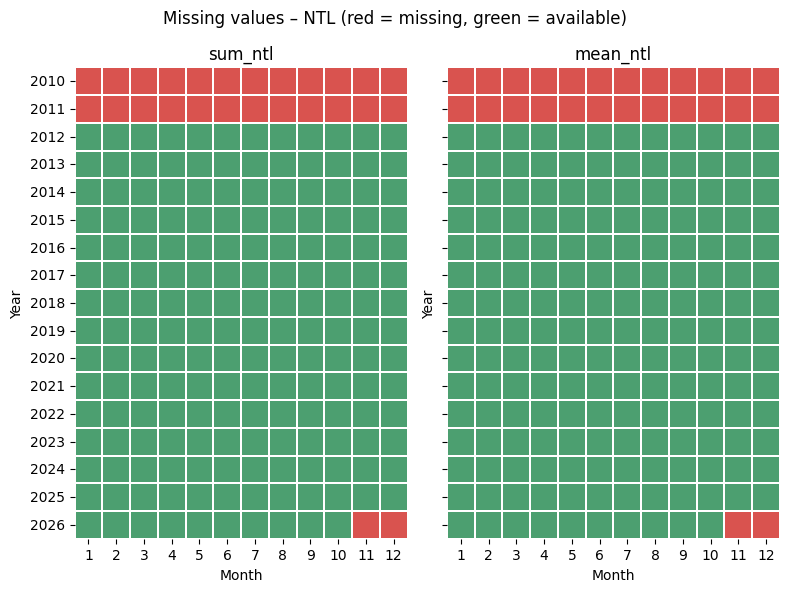

In [9]:
# ---- Choose the dataframe to inspect ----
df_check = df_ntl         # or df_ndvi, df_no2, df_ntl, general_df
name = "NTL"

# Columns to check: everything except the date helpers
cols = [c for c in df_check.columns if c not in ['date', 'year', 'month', 'YearMonth']]

# ---- 1. Count missing values per column ----
print(df_check[cols].isna().sum())

# ---- 2. Year x month grid of missing values, one panel per column ----
df_plot = df_check.copy()
df_plot['year'] = df_plot['date'].dt.year
df_plot['month'] = df_plot['date'].dt.month

n = len(cols)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 6), sharey=True, squeeze=False)

for ax, col in zip(axes[0], cols):
    # 1 = missing, 0 = present; months absent from the file also show as missing
    grid = df_plot.pivot_table(index='year', columns='month', values=col,
                               aggfunc=lambda x: x.isna().mean(), dropna=False)
    grid = grid.reindex(columns=range(1, 13)).fillna(1)
    sns.heatmap(grid, ax=ax, cmap=['#4c9f70', '#d9534f'], vmin=0, vmax=1,
                cbar=False, linewidths=0.3, linecolor='white')
    ax.set_title(col)
    ax.set_xlabel('Month')
    ax.set_ylabel('Year')

fig.suptitle(f"Missing values – {name} (red = missing, green = available)")
plt.tight_layout()
plt.show()

### Impute missing values

Here the gaps are at the start of the sample (2010–2012), when the satellite product does not yet cover the full period.

We fill each missing month with the **average of the same calendar month in the other years**. This is simple and keeps the seasonal pattern, but note two caveats:
- it uses information from later years (fine for a historical training sample, not for a real-time nowcast);
- imputed months carry no real year-to-year signal, so their YoY changes are artificial.

In [10]:
ntl_cols = ['mean_ntl', 'sum_ntl']
print("Missing values before imputation:\n", df_ntl[ntl_cols].isna().sum())

same_month_mean = df_ntl.groupby('month')[ntl_cols].transform('mean')
df_ntl[ntl_cols] = df_ntl[ntl_cols].fillna(same_month_mean)

print("\nMissing values after imputation:\n", df_ntl[ntl_cols].isna().sum())

Missing values before imputation:
 mean_ntl    26
sum_ntl     26
dtype: int64

Missing values after imputation:
 mean_ntl    0
sum_ntl     0
dtype: int64


#### ❓ What other methods would you use to impute the missing values? What would change if you only used past data?

### 2.2 FAO vegetation indicators (ASI, NDVI anomaly, VHI)
One option is to forward-fill gaps (carry the last observed value forward). Keep in mind that this also carries the last in-season value through the winter.

Here, the Agricultural Stress Index (ASI) is only computed **during the crop season**, so blank months in winter mean *"not applicable"*, not *"missing"*.

In [11]:
df_fao = add_date(df_fao)
df_fao = df_fao.sort_values('date')
print("Missing values before filling:\n", df_fao.isna().sum())
df_fao.head()

Missing values before filling:
 YearMonth             0
sum_asi              66
mean_asi             66
sum_ndvi_anomaly      0
mean_ndvi_anomaly     0
sum_vhi               0
mean_vhi              0
year                  0
month                 0
date                  0
dtype: int64


,YearMonth,sum_asi,mean_asi,sum_ndvi_anomaly,mean_ndvi_anomaly,sum_vhi,mean_vhi,year,month,date
0,2010-01-01,NaN,NaN,0.156,0.002889,32.664,0.494909,2010,1,2010-01-01
1,2010-02-01,NaN,NaN,0.433,0.008019,30.901,0.468197,2010,2,2010-02-01
2,2010-03-01,32.581,3.258100,2.686,0.049741,38.858,0.588758,2010,3,2010-03-01
3,2010-04-01,117.980,2.457917,10.027,0.185685,45.054,0.682636,2010,4,2010-04-01
4,2010-05-01,342.225,6.337500,16.987,0.314574,34.111,0.516833,2010,5,2010-05-01


sum_asi              66
mean_asi             66
sum_ndvi_anomaly      0
mean_ndvi_anomaly     0
sum_vhi               0
mean_vhi              0
dtype: int64


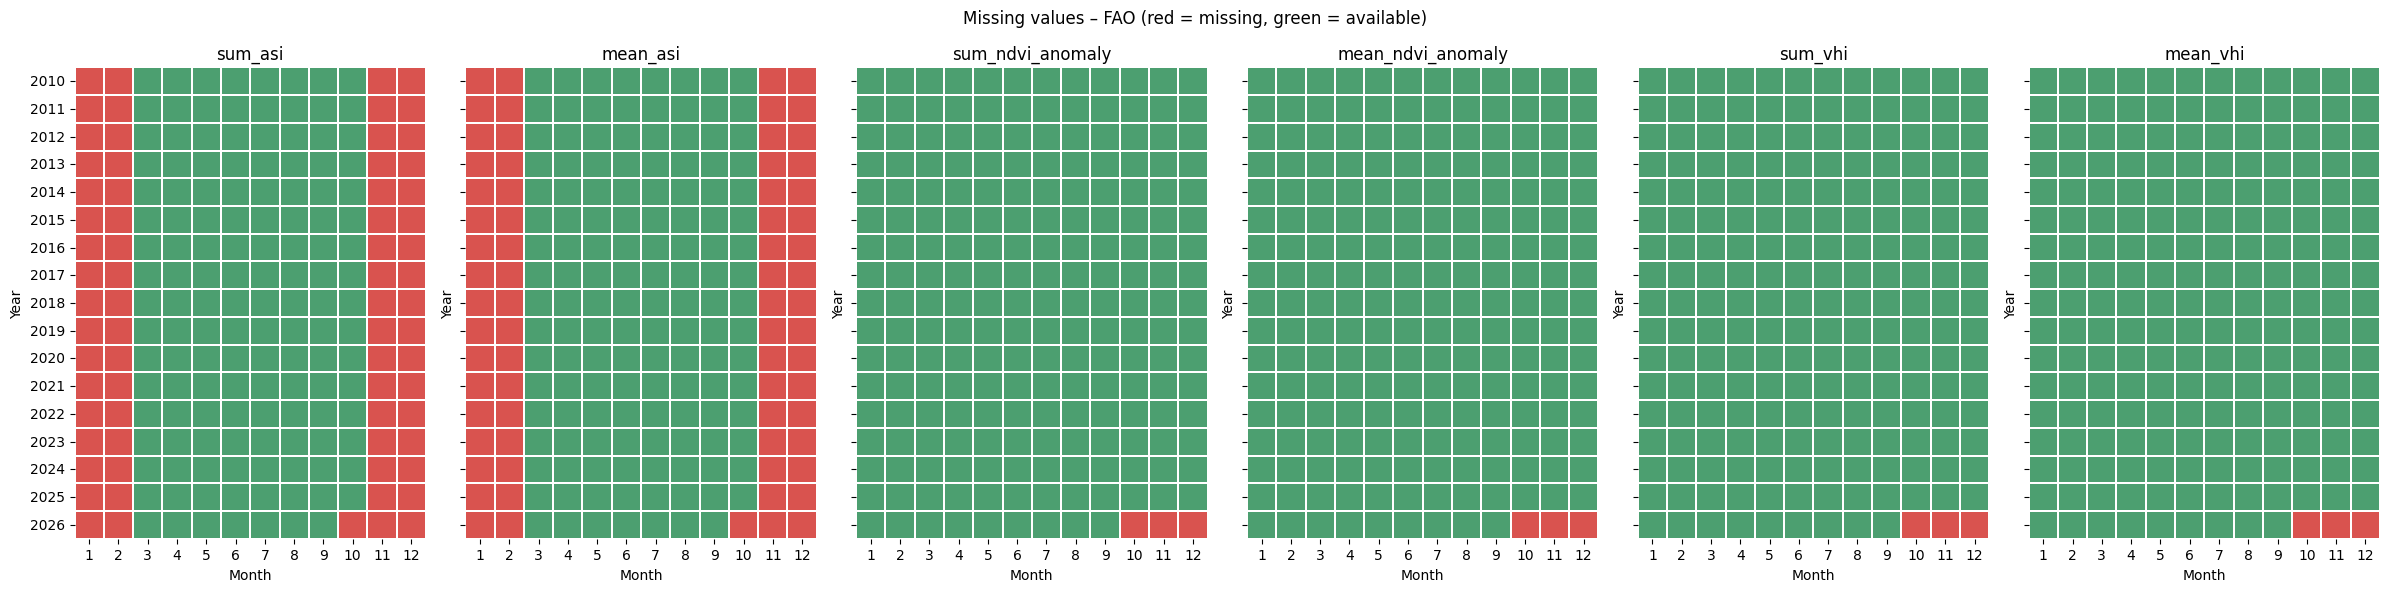

In [12]:
# ---- Choose the dataframe to inspect ----
df_check = df_fao         # or df_ndvi, df_no2, df_ntl, general_df
name = "FAO"

# Columns to check: everything except the date helpers
cols = [c for c in df_check.columns if c not in ['date', 'year', 'month', 'YearMonth']]

# ---- 1. Count missing values per column ----
print(df_check[cols].isna().sum())

# ---- 2. Year x month grid of missing values, one panel per column ----
df_plot = df_check.copy()
df_plot['year'] = df_plot['date'].dt.year
df_plot['month'] = df_plot['date'].dt.month

n = len(cols)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 6), sharey=True, squeeze=False)

for ax, col in zip(axes[0], cols):
    # 1 = missing, 0 = present; months absent from the file also show as missing
    grid = df_plot.pivot_table(index='year', columns='month', values=col,
                               aggfunc=lambda x: x.isna().mean(), dropna=False)
    grid = grid.reindex(columns=range(1, 13)).fillna(1)
    sns.heatmap(grid, ax=ax, cmap=['#4c9f70', '#d9534f'], vmin=0, vmax=1,
                cbar=False, linewidths=0.3, linecolor='white')
    ax.set_title(col)
    ax.set_xlabel('Month')
    ax.set_ylabel('Year')

fig.suptitle(f"Missing values – {name} (red = missing, green = available)")
plt.tight_layout()
plt.show()

#### ❓ What alternative could better represent the off-season months for ASI (e.g., 0, or a separate in-season flag)?

### 2.3 Other indicators: NO₂, NDVI, EVI, precipitation, Google Trends


=== NO2 ===
sum_no2     0
mean_no2    0
dtype: int64


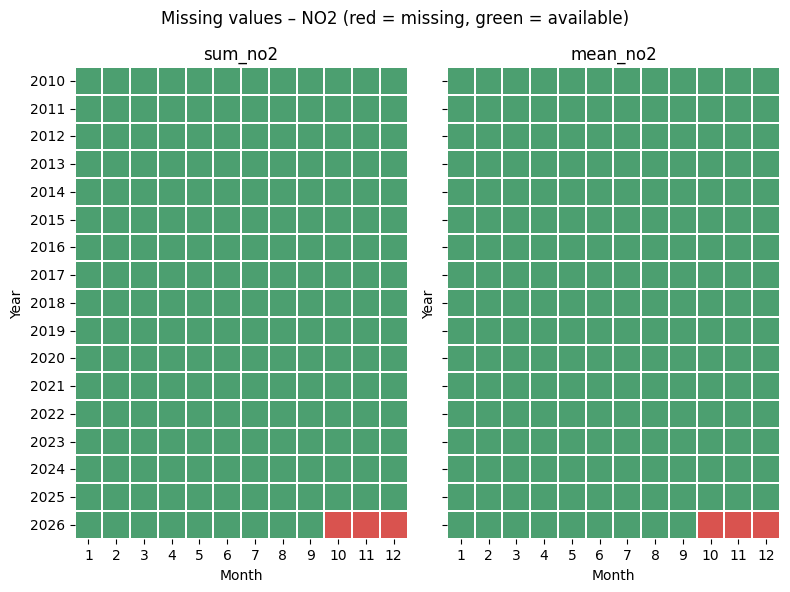


=== NDVI ===
sum_ndvi     3
mean_ndvi    3
dtype: int64


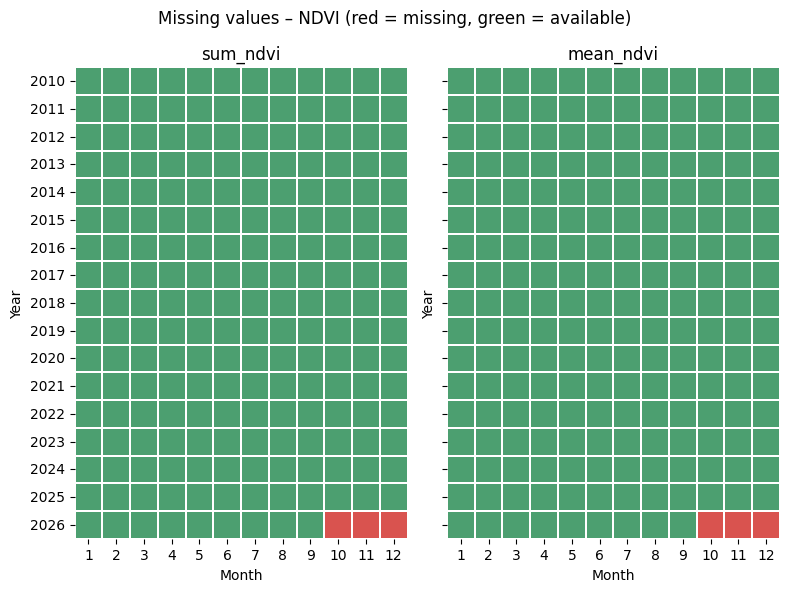


=== EVI ===
sum_evi     3
mean_evi    3
dtype: int64


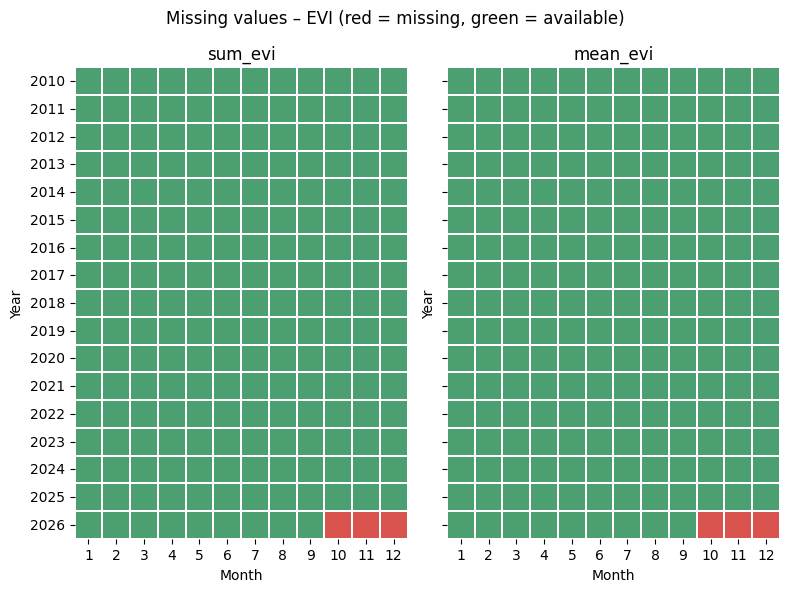


=== Precipitation ===
sum_pcp     3
mean_pcp    3
dtype: int64


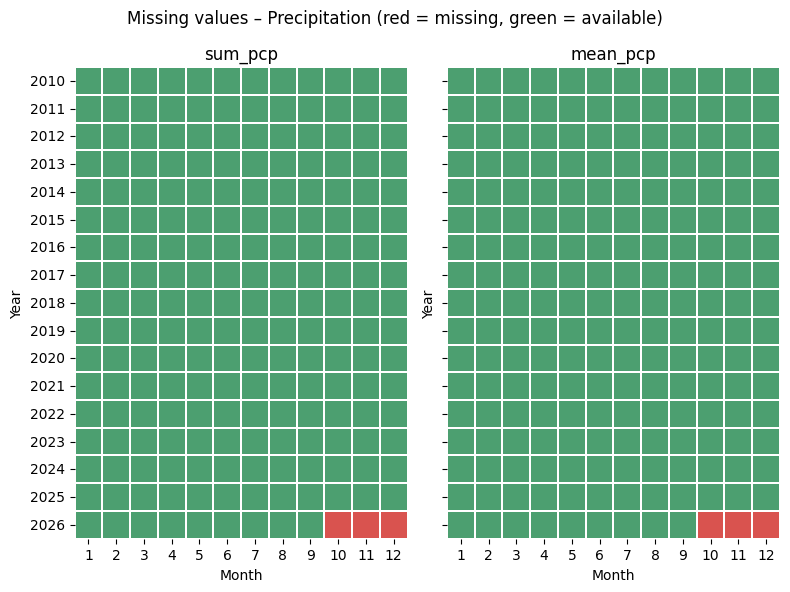


=== Google Trends ===
gti_tourism    0
dtype: int64


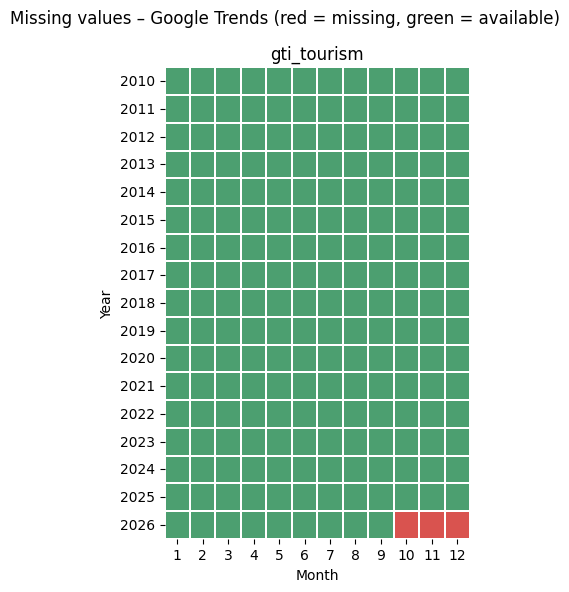

In [13]:
# ---- Missing-value check for all indicator dataframes ----
# Run after the loading cells (2.1–2.3) and BEFORE any imputation or filling

dfs_to_check = {
    # "Night-time lights": df_ntl,
    # "FAO vegetation indices": df_fao,
    "NO2": df_no2,
    "NDVI": df_ndvi,
    "EVI": df_evi,
    "Precipitation": df_pcp,
    "Google Trends": df_gti,
}

for name, df_check in dfs_to_check.items():

    # Make sure there is a date column (works even straight after read_csv)
    if 'date' not in df_check.columns:
        df_check = add_date(df_check.copy())

    df_plot = df_check.copy()
    df_plot['year'] = df_plot['date'].dt.year
    df_plot['month'] = df_plot['date'].dt.month

    # Columns to check: everything except the date helpers
    cols = [c for c in df_plot.columns if c not in ['date', 'year', 'month', 'YearMonth']]

    print(f"\n=== {name} ===")
    print(df_plot[cols].isna().sum())

    # Year x month grid, one panel per column (1 = missing, 0 = present)
    n = len(cols)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 6), sharey=True, squeeze=False)

    for ax, col in zip(axes[0], cols):
        grid = df_plot.pivot_table(index='year', columns='month', values=col,
                                   aggfunc=lambda x: x.isna().mean(), dropna=False)
        grid = grid.reindex(columns=range(1, 13)).fillna(1)   # months with no row count as missing
        sns.heatmap(grid, ax=ax, cmap=['#4c9f70', '#d9534f'], vmin=0, vmax=1,
                    cbar=False, linewidths=0.3, linecolor='white')
        ax.set_title(col)
        ax.set_xlabel('Month')
        ax.set_ylabel('Year')

    fig.suptitle(f"Missing values – {name} (red = missing, green = available)")
    plt.tight_layout()
    plt.show()

## 3. Combine all indicators on the date and explore
We start from NTL and add each source with a **left merge on `date`**. The check at the end confirms that no rows were added or lost.

In [14]:
# general_df = df_ntl[['date', 'year', 'month'] + ntl_cols].copy()

# sources = [
#     (df_evi,  ['sum_evi', 'mean_evi']),
#     (df_ndvi, ['mean_ndvi', 'sum_ndvi']),
#     (df_no2,  ['mean_no2', 'sum_no2']),
#     (df_pcp,  ['mean_pcp', 'sum_pcp']),
#     (df_fao,  ['sum_asi', 'mean_asi', 'sum_ndvi_anomaly', 'mean_ndvi_anomaly', 'sum_vhi', 'mean_vhi']),
#     (df_gti,  ['gti_tourism']),
# ]
# for df_src, cols in sources:
#     general_df = general_df.merge(df_src[['date'] + cols], on='date', how='left')

# general_df = general_df.sort_values('date').reset_index(drop=True)
# assert len(general_df) == len(df_ntl), "Row count changed during merge: check for duplicate dates"
# assert general_df['date'].is_unique

# print(general_df['date'].min().date(), "to", general_df['date'].max().date(), "|", len(general_df), "months")
# general_df.head()


# general_df = df_ntl[['date', 'year', 'month'] + ntl_cols].copy()

# sources = [
#     (df_evi,  ['sum_evi', 'mean_evi']),
#     (df_ndvi, ['mean_ndvi', 'sum_ndvi']),
#     (df_no2,  ['mean_no2', 'sum_no2']),
#     (df_pcp,  ['mean_pcp', 'sum_pcp']),
#     (df_fao,  ['sum_asi', 'mean_asi', 'sum_ndvi_anomaly', 'mean_ndvi_anomaly', 'sum_vhi', 'mean_vhi']),
#     (df_gti,  ['gti_tourism']),
# ]
# for df_src, cols in sources:
#     general_df = general_df.merge(df_src[['date'] + cols], on='date', how='left')

# general_df = general_df.sort_values('date').reset_index(drop=True)

# # Keep data through the cutoff month (e.g., drop partial October data when nowcasting Q3)
# cutoff = pd.Period(year=cutoffYear, month=cutoffMonth, freq='M')
# n_before = len(general_df)
# general_df = general_df[general_df['date'].dt.to_period('M') <= cutoff].reset_index(drop=True)
# print(f"Kept data through {cutoff.strftime('%B %Y')}; dropped {n_before - len(general_df)} later month(s)")

# # Check: exactly one row per month, with no gaps
# expected_months = pd.period_range(general_df['date'].min(), general_df['date'].max(), freq='M')
# assert general_df['date'].is_unique, "Duplicate months found: check the source files for repeated dates"
# assert len(general_df) == len(expected_months), "Some months are missing between the first and last date"

# print(general_df['date'].min().date(), "to", general_df['date'].max().date(), "|", len(general_df), "months")
# general_df.head()

# Start with the monthly NTL calendar
general_df = df_ntl[
    ['date', 'year', 'month'] + ntl_cols
].copy()

# Indicators to add
sources = [
    (df_evi,  ['sum_evi', 'mean_evi']),
    (df_ndvi, ['mean_ndvi', 'sum_ndvi']),
    (df_no2,  ['mean_no2', 'sum_no2']),
    (df_pcp,  ['mean_pcp', 'sum_pcp']),
    (df_fao,  ['sum_asi', 'mean_asi', 'sum_ndvi_anomaly', 'mean_ndvi_anomaly', 'sum_vhi', 'mean_vhi']),
    (df_gti,  ['gti_tourism']),
]

# Merge every source onto the monthly calendar
for df_src, cols in sources:
    general_df = general_df.merge(
        df_src[['date'] + cols],
        on='date',
        how='left'
    )

general_df = (general_df.sort_values('date').reset_index(drop=True))

# Keep data only through the selected nowcast cutoff
cutoff = pd.Period(year=cutoffYear,month=cutoffMonth,freq='M')

n_before = len(general_df)

general_df = general_df[
    general_df['date'].dt.to_period('M') <= cutoff
].reset_index(drop=True)

print(
    f"Kept data through {cutoff.strftime('%B %Y')}; "
    f"dropped {n_before - len(general_df)} later month(s)"
)

# Check that there is exactly one row for every month
expected_months = pd.period_range(
    general_df['date'].min(),
    general_df['date'].max(),
    freq='M'
)

assert general_df['date'].is_unique, ("Duplicate months found: check source files for repeated dates")

assert len(general_df) == len(expected_months), ("Some months are missing between the first and last date")

print(general_df['date'].min().date(),"to",general_df['date'].max().date(),
    "|",len(general_df),"months")

general_df.head()


Kept data through September 2026; dropped 3 later month(s)
2010-01-01 to 2026-09-01 | 201 months


,date,year,month,mean_ntl,sum_ntl,sum_evi,mean_evi,mean_ndvi,sum_ndvi,mean_no2,sum_no2,mean_pcp,sum_pcp,sum_asi,mean_asi,sum_ndvi_anomaly,mean_ndvi_anomaly,sum_vhi,mean_vhi,gti_tourism
0,2010-01-01,2010,1,7.402706,677592.600725,2.071730e+07,226.438670,326.253035,2.984950e+07,0.0002,9.2262,1.970638,1.690585e+05,NaN,NaN,0.156,0.002889,32.664,0.494909,7.0
1,2010-02-01,2010,2,5.737802,525198.854434,3.385190e+07,369.943498,530.749996,4.856659e+07,0.0002,7.7959,2.413723,2.070702e+05,NaN,NaN,0.433,0.008019,30.901,0.468197,5.0
2,2010-03-01,2010,3,5.681804,520073.144941,4.656529e+07,508.762421,785.567533,7.190032e+07,0.0002,10.8220,4.401307,3.775824e+05,32.581,3.258100,2.686,0.049741,38.858,0.588758,8.0
3,2010-04-01,2010,4,5.581392,510882.123595,7.007009e+07,765.531036,1279.269012,1.170932e+08,0.0003,15.6934,5.199207,4.460332e+05,117.980,2.457917,10.027,0.185685,45.054,0.682636,8.0
4,2010-05-01,2010,5,4.860489,444895.657014,9.445687e+07,1032.133315,1737.910268,1.590469e+08,0.0006,31.7400,18.990313,1.629154e+06,342.225,6.337500,16.987,0.314574,34.111,0.516833,9.0


In [15]:
general_df.tail(10)

,date,year,month,mean_ntl,sum_ntl,sum_evi,mean_evi,mean_ndvi,sum_ndvi,mean_no2,sum_no2,mean_pcp,sum_pcp,sum_asi,mean_asi,sum_ndvi_anomaly,mean_ndvi_anomaly,sum_vhi,mean_vhi,gti_tourism
191,2025-12-01,2025,12,7.445717,6.815296e+05,4.983753e+07,544.528874,870.349413,7.965797e+07,0.0000,2.3745,2.465159,2.114828e+05,NaN,NaN,4.516,0.096085,27.249,0.412864,100.0
192,2026-01-01,2026,1,11.491651,1.051866e+06,3.580836e+07,391.298088,611.732102,5.598066e+07,0.0000,-1.3702,1.780294,1.527291e+05,NaN,NaN,2.581,0.051620,30.598,0.463606,82.0
193,2026-02-01,2026,2,8.441962,7.727190e+05,4.152245e+07,453.690516,719.163805,6.581897e+07,0.0000,3.2954,2.363744,2.027825e+05,NaN,NaN,1.179,0.022245,29.843,0.452167,66.0
194,2026-03-01,2026,3,5.913303,5.412630e+05,7.075138e+07,772.999285,1286.476771,1.177491e+08,0.0002,15.0714,2.697136,2.313838e+05,52.258,5.225800,5.607,0.103833,32.905,0.498561,42.0
195,2026-04-01,2026,4,5.179090,4.740581e+05,8.114390e+07,886.509375,1505.273046,1.377805e+08,0.0002,17.9749,5.637993,4.836760e+05,431.197,8.983271,14.762,0.273370,38.034,0.576273,42.0
196,2026-05-01,2026,5,4.225620,3.867841e+05,1.099516e+08,1202.345633,2008.164577,1.836418e+08,0.0003,23.6086,17.066698,1.464130e+06,420.733,7.791352,19.995,0.370278,38.708,0.586485,49.0
197,2026-06-01,2026,6,3.006599,2.752033e+05,1.594791e+08,1746.627625,2835.860608,2.589333e+08,0.0003,25.2922,30.525456,2.618739e+06,263.024,4.870815,30.548,0.565704,41.858,0.634212,45.0
198,2026-07-01,2026,7,2.723713,2.493099e+05,1.943069e+08,2125.828257,3436.041969,3.140643e+08,0.0003,30.2842,45.820192,3.930854e+06,226.602,4.196333,36.675,0.679167,37.862,0.573667,33.0
199,2026-08-01,2026,8,6.081070,5.566192e+05,1.944638e+08,2129.075263,3537.731944,3.231265e+08,0.0004,32.7129,50.237603,4.309818e+06,193.441,3.582241,38.723,0.717093,38.070,0.576818,22.0
200,2026-09-01,2026,9,7.098063,6.497078e+05,1.561244e+08,1710.427540,3047.283605,2.781495e+08,0.0001,9.0814,13.335558,1.144040e+06,160.726,2.398896,46.368,0.515200,51.684,0.469855,24.0


In [16]:
# Drop months after the cutoff (e.g., partial October data when nowcasting Q3)
cutoff = pd.Period(year=cutoffYear, month=cutoffMonth, freq='M')

n_before = len(general_df)
general_df = general_df[general_df['date'].dt.to_period('M') <= cutoff].reset_index(drop=True)
print(f"Kept data through {cutoff.strftime('%B %Y')}; dropped {n_before - len(general_df)} later month(s)")

Kept data through September 2026; dropped 0 later month(s)


### 3.1 Let's examine the indicators further

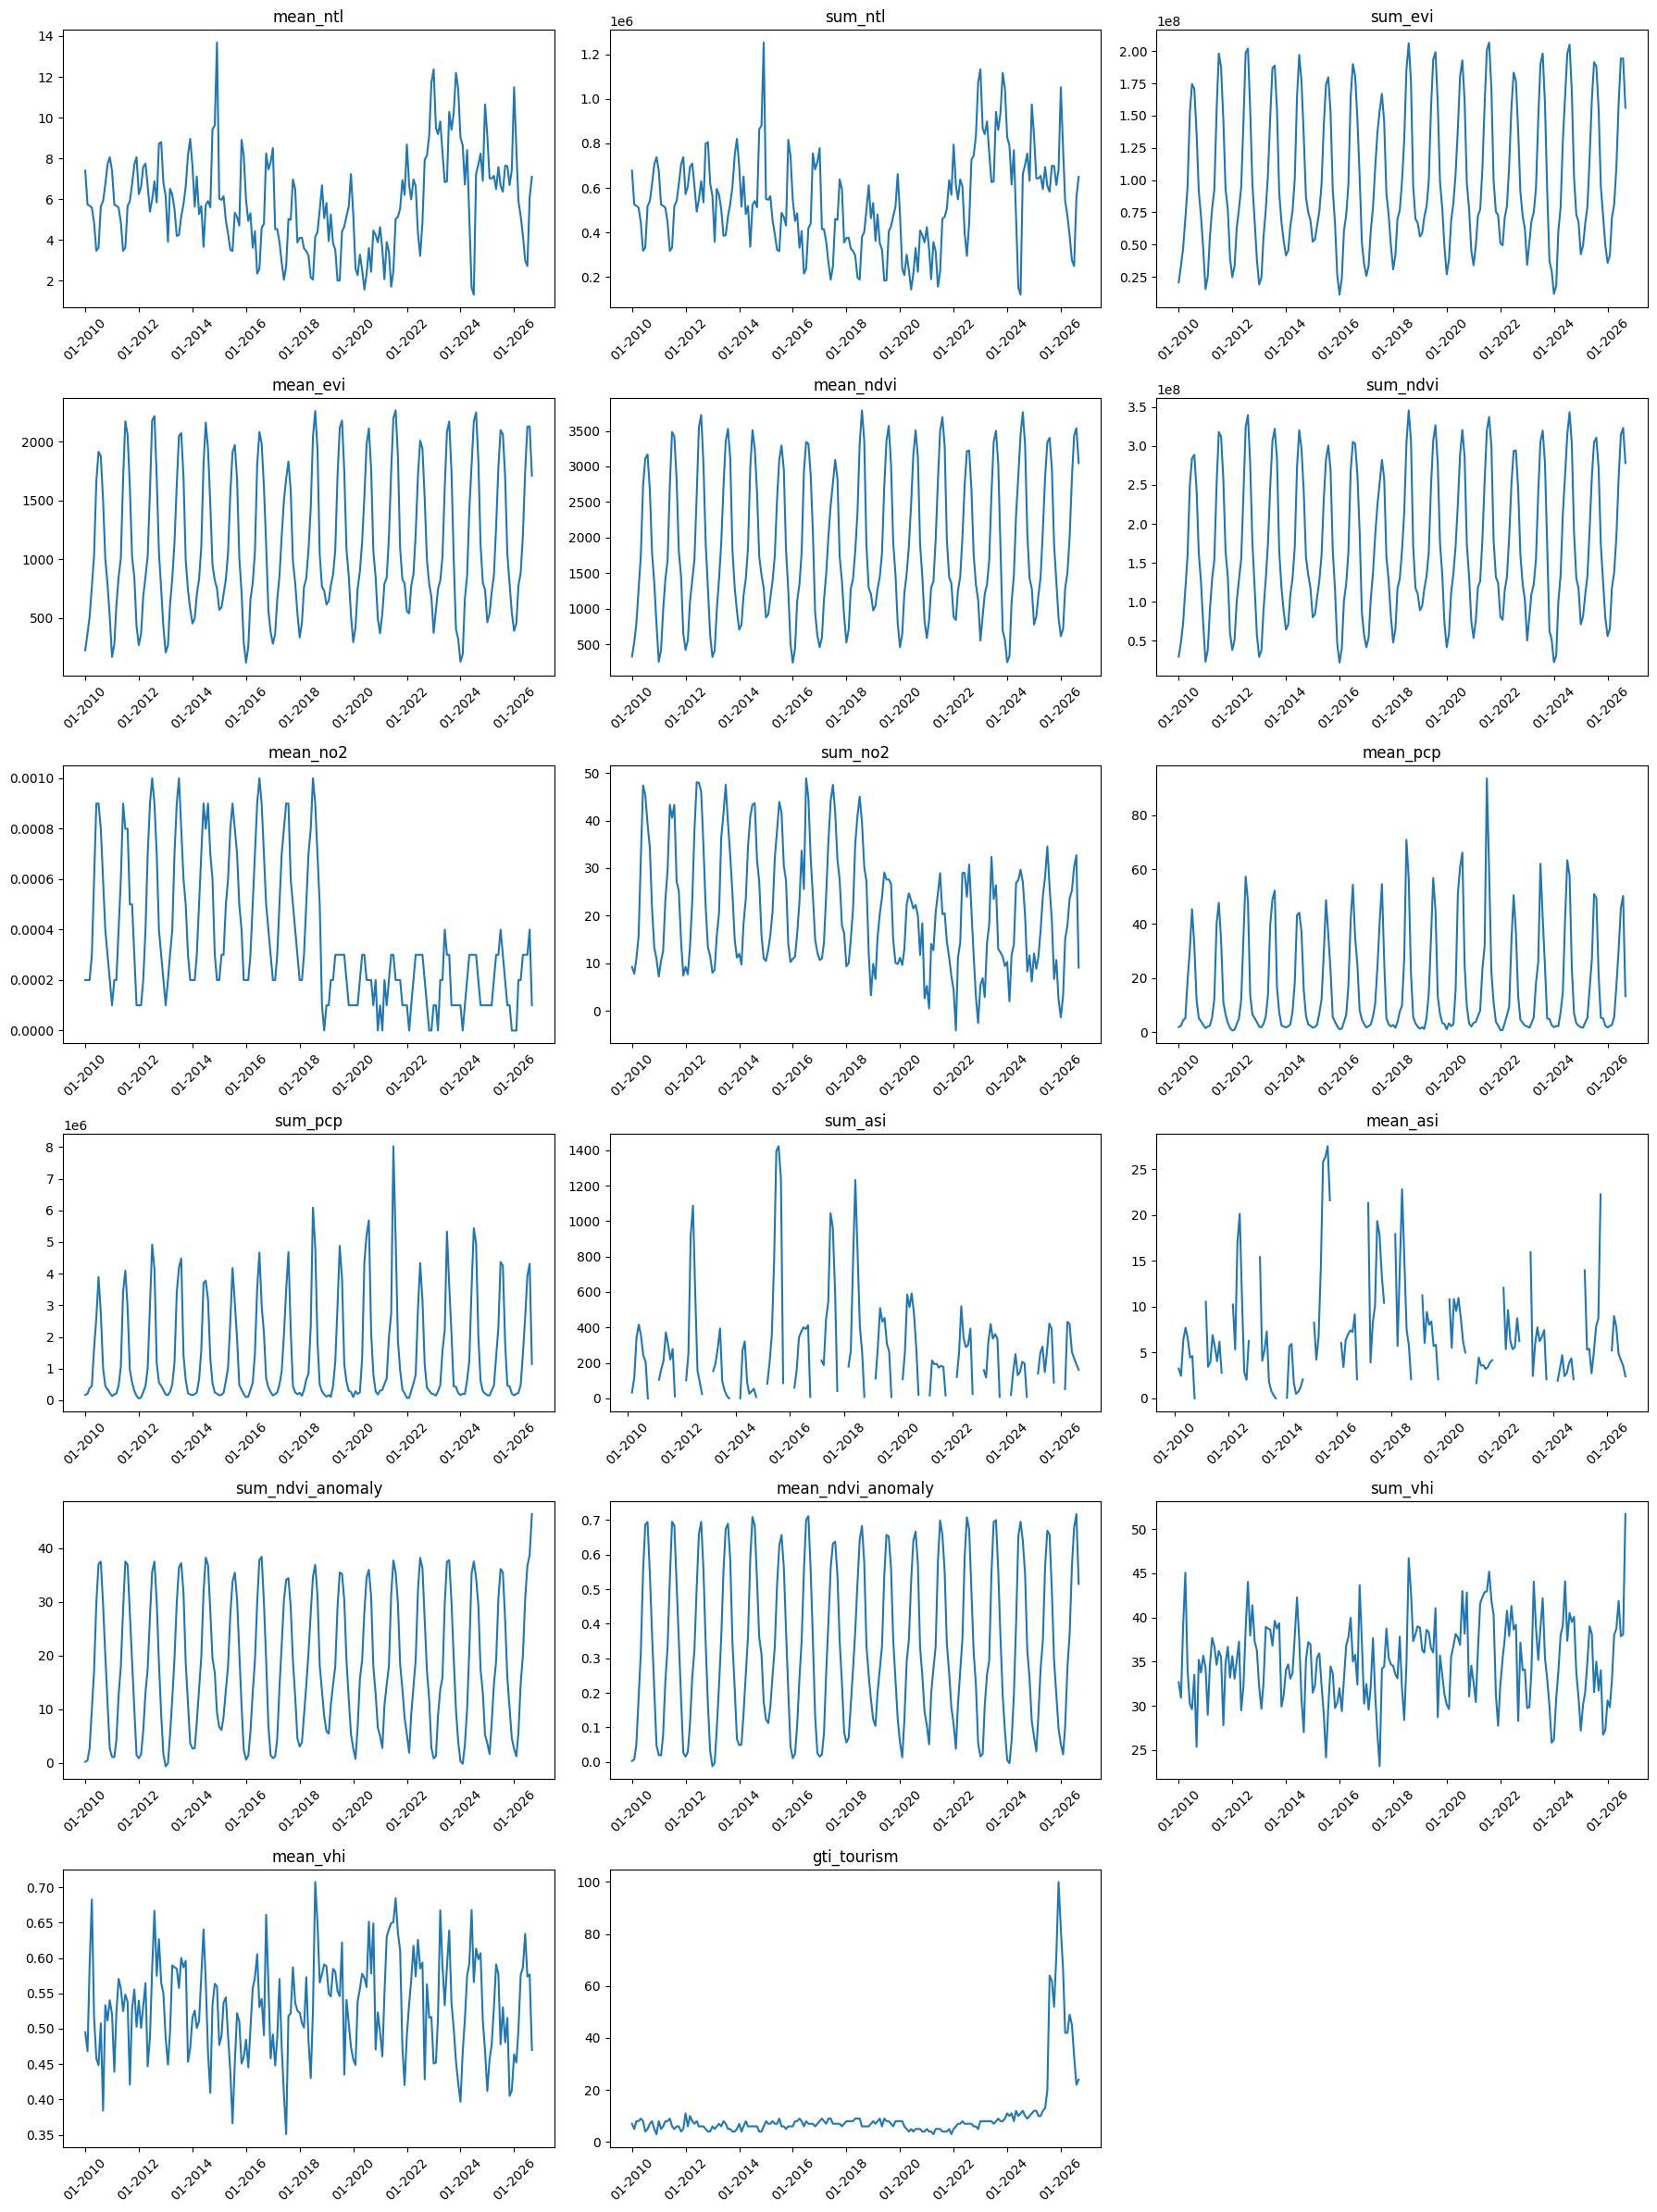

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Create dates from year and month for plotting
plot_dates = pd.to_datetime(
    general_df[['year', 'month']].assign(day=1)
)

# Exclude non-feature columns from plotting
plot_cols = [
    col for col in general_df.columns
    if col not in ['date', 'GDP', 'year', 'month']
]

# Calculate subplot layout
num_cols = len(plot_cols)
num_rows = (num_cols + 2) // 3

fig, axes = plt.subplots(num_rows, 3, figsize=(18, num_rows * 4))
axes = axes.flatten()

# Plot each variable against date
for i, column in enumerate(plot_cols):
    axes[i].plot(plot_dates, general_df[column])

    axes[i].set_title(column)
    axes[i].set_xlabel('')

    # Display x-axis as mm-yyyy
    axes[i].xaxis.set_major_formatter(mdates.DateFormatter('%m-%Y'))
    axes[i].tick_params(axis='x', rotation=45)

# Hide unused subplots
for j in range(len(plot_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# num_cols = len(general_df.columns)
# num_rows = (num_cols + 2) // 3  # Adjust the number of rows dynamically

# fig, axes = plt.subplots(num_rows, 3, figsize=(18, num_rows * 4))
# axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

# # Exclude 'date', 'gdp', 'gdp_1', 'gdp_2', 'gdp_3' from plotting
# plot_cols = [col for col in general_df.columns if col not in ['date', 'GDP', 'year', 'month']]
# #plot_cols = [col for col in df_stationary_complete.columns]

# for i, column in enumerate(plot_cols):
#     general_df[column].plot(ax=axes[i], title=column)
#     axes[i].set_xlabel('') # Remove x-axis label for cleaner look

# # Hide any unused subplots
# for j in range(i + 1, len(axes)):
#     fig.delaxes(axes[j])

# plt.tight_layout()
# plt.show()

In [18]:
general_df.describe()

,date,year,month,mean_ntl,sum_ntl,sum_evi,mean_evi,mean_ndvi,sum_ndvi,mean_no2,sum_no2,mean_pcp,sum_pcp,sum_asi,mean_asi,sum_ndvi_anomaly,mean_ndvi_anomaly,sum_vhi,mean_vhi,gti_tourism
count,201,201.000000,201.000000,201.000000,2.010000e+02,2.010000e+02,201.000000,201.000000,2.010000e+02,201.000000,201.000000,201.000000,2.010000e+02,135.000000,135.000000,201.000000,201.000000,201.000000,201.000000,201.000000
mean,2018-05-01 22:05:22.388059648,2017.880597,6.432836,5.871307,5.374189e+05,1.015299e+08,1111.580638,1858.520028,1.697491e+08,0.000352,20.954068,16.522416,1.417436e+06,295.461467,7.304804,17.715965,0.327826,35.154612,0.531247,10.303483
min,2010-01-01 00:00:00,2010.000000,1.000000,1.318780,1.207120e+05,1.113314e+07,121.713497,241.558313,2.209535e+07,0.000000,-4.125100,0.674204,5.783912e+04,0.000000,0.000000,-0.665000,-0.012315,23.155000,0.350833,3.000000
25%,2014-03-01 00:00:00,2014.000000,3.000000,4.225620,3.867841e+05,5.994591e+07,654.940175,1093.251196,1.000676e+08,0.000200,11.146400,2.753344,2.362058e+05,110.242500,3.577759,5.871000,0.117955,31.982000,0.480788,6.000000
50%,2018-05-01 00:00:00,2018.000000,6.000000,5.722434,5.237922e+05,8.667293e+07,952.053124,1677.379489,1.533951e+08,0.000300,18.884300,6.194360,5.314060e+05,240.577000,5.840978,15.875000,0.293981,35.187000,0.531591,7.000000
75%,2022-07-01 00:00:00,2022.000000,9.000000,7.241459,6.628332e+05,1.542773e+08,1693.324570,2827.855693,2.579632e+08,0.000500,28.998700,25.822532,2.215281e+06,392.020500,8.905959,29.883000,0.553370,38.105000,0.577273,8.000000
max,2026-09-01 00:00:00,2026.000000,12.000000,13.684178,1.252555e+06,2.067365e+08,2264.588512,3787.458135,3.454606e+08,0.001000,48.873800,93.563631,8.026701e+06,1422.360000,27.509667,46.368000,0.717093,51.684000,0.707515,100.000000
std,NaN,4.848265,3.440453,2.315929,2.119842e+05,5.534281e+07,606.918963,1012.635717,9.232867e+07,0.000271,12.412336,18.991021,1.629215e+06,281.770576,5.709967,12.689627,0.231185,4.654619,0.068100,13.388519


### 3.2 Correlations

In [19]:
correlation_matrix = general_df.corr(numeric_only=True)
display(correlation_matrix)

,year,month,mean_ntl,sum_ntl,sum_evi,mean_evi,mean_ndvi,sum_ndvi,mean_no2,sum_no2,mean_pcp,sum_pcp,sum_asi,mean_asi,sum_ndvi_anomaly,mean_ndvi_anomaly,sum_vhi,mean_vhi,gti_tourism
year,1.000000,-0.032857,0.106420,0.106420,0.074533,0.073768,0.068399,0.069179,-0.496865,-0.306413,0.060466,0.060466,-0.060144,-0.026361,0.045376,0.037361,0.097327,0.064763,0.440393
month,-0.032857,1.000000,0.191808,0.191808,0.315501,0.316036,0.350659,0.350203,0.129438,0.150544,0.161202,0.161202,-0.009893,-0.093078,0.338548,0.343016,0.086701,0.076437,-0.006882
mean_ntl,0.106420,0.191808,1.000000,1.000000,-0.393566,-0.393074,-0.369640,-0.370148,-0.384017,-0.464356,-0.438641,-0.438641,-0.316811,-0.156956,-0.394769,-0.401447,-0.159824,-0.172048,0.129164
sum_ntl,0.106420,0.191808,1.000000,1.000000,-0.393566,-0.393074,-0.369640,-0.370148,-0.384017,-0.464356,-0.438641,-0.438641,-0.316811,-0.156956,-0.394769,-0.401447,-0.159824,-0.172048,0.129164
sum_evi,0.074533,0.315501,-0.393566,-0.393566,1.000000,0.999997,0.996314,0.996417,0.602261,0.777686,0.890891,0.890891,0.311092,-0.033204,0.977498,0.981140,0.379470,0.367235,-0.008414
mean_evi,0.073768,0.316036,-0.393074,-0.393074,0.999997,1.000000,0.996424,0.996520,0.602867,0.777959,0.890648,0.890648,0.310727,-0.033127,0.977639,0.981279,0.378874,0.366616,-0.008571
mean_ndvi,0.068399,0.350659,-0.369640,-0.369640,0.996314,0.996424,1.000000,0.999997,0.605021,0.773783,0.862654,0.862654,0.288830,-0.045677,0.979960,0.982193,0.381023,0.364576,-0.009726
sum_ndvi,0.069179,0.350203,-0.370148,-0.370148,0.996417,0.996520,0.999997,1.000000,0.604488,0.773593,0.862964,0.862964,0.289270,-0.045773,0.979924,0.982157,0.381664,0.365234,-0.009566
mean_no2,-0.496865,0.129438,-0.384017,-0.384017,0.602261,0.602867,0.605021,0.604488,1.000000,0.922087,0.548555,0.548555,0.433818,0.175313,0.635223,0.646849,0.031259,0.051579,-0.195381
sum_no2,-0.306413,0.150544,-0.464356,-0.464356,0.777686,0.777959,0.773783,0.773593,0.922087,1.000000,0.702593,0.702593,0.496948,0.134757,0.804768,0.818758,0.124577,0.148821,-0.151043


In [20]:
## Uncomment to visualize correlation heatmap
# plt.figure(figsize=(12, 10))
# sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
# plt.title('Correlation Matrix Heatmap')
# plt.show()

In [21]:
df_m = general_df.copy()

## We skip this step as we are not dropping any features at the moment
# df_m = df_m.drop(columns=['sum_no2', 'sum_ntl',
#                           'sum_evi', 'sum_ndvi',
#                           'sum_pcp', 'sum_asi',
#                           'sum_ndvi_anomaly','sum_vhi',
#                           ])

### 3.3 Identify unusual observations
Before transforming the indicators, we use the IQR rule as a simple diagnostic to identify observations that are unusually high or low relative to the overall distribution of each series.
Important: a flagged observation is not necessarily a data error and should not automatically be removed. In a time series, an unusual value may represent a genuine economic or environmental event, seasonality, a structural change, or a measurement problem. We therefore flag these observations for inspection rather than modifying them.

In [22]:
outlier_thres = 3

=== Outlier Detection Summary (IQR Method) ===


,Lower Bound,Upper Bound,Outlier Count,Outlier %
year,1.990000e+03,2.046000e+03,0.0,0.00
month,-1.500000e+01,2.700000e+01,0.0,0.00
mean_ntl,-4.821900e+00,1.628900e+01,0.0,0.00
sum_ntl,-4.413634e+05,1.490981e+06,0.0,0.00
sum_evi,-2.230483e+08,4.372716e+08,0.0,0.00
mean_evi,-2.460213e+03,4.808478e+03,0.0,0.00
mean_ndvi,-4.110562e+03,8.031669e+03,0.0,0.00
sum_ndvi,-3.736193e+08,7.316500e+08,0.0,0.00
mean_no2,-7.000000e-04,1.400000e-03,0.0,0.00
sum_no2,-4.241050e+01,8.255560e+01,0.0,0.00


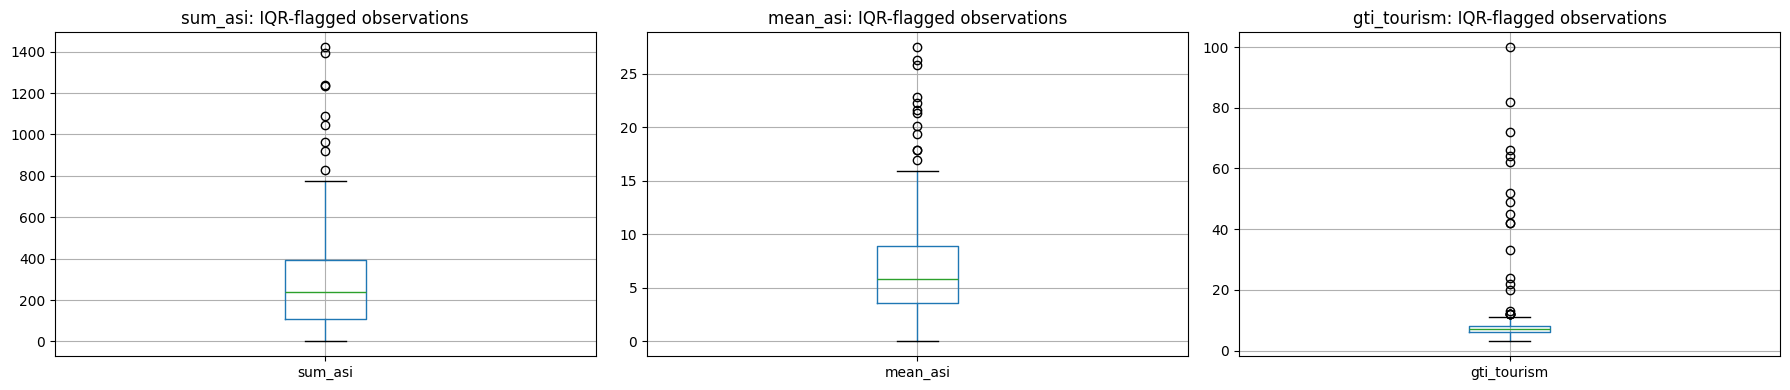

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Define an IQR-based function to flag outliers
def detect_outliers_iqr(df):
    outlier_summary = {}
    outliers_mask = pd.DataFrame(False, index=df.index, columns=df.columns)

    for col in df.select_dtypes(include=[np.number]).columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - outlier_thres * iqr
        upper_bound = q3 + outlier_thres * iqr

        # Flag values outside bounds (excluding NaNs)
        is_outlier = (df[col] < lower_bound) | (df[col] > upper_bound)
        outliers_mask[col] = is_outlier & df[col].notna()

        num_outliers = outliers_mask[col].sum()
        total_non_nan = df[col].notna().sum()
        pct_outliers = (num_outliers / total_non_nan * 100) if total_non_nan > 0 else 0

        outlier_summary[col] = {
            'Lower Bound': round(lower_bound, 4),
            'Upper Bound': round(upper_bound, 4),
            'Outlier Count': num_outliers,
            'Outlier %': round(pct_outliers, 2)
        }

    return pd.DataFrame(outlier_summary).T, outliers_mask

# 2. Run outlier detection on df_m
summary_df, outliers_mask = detect_outliers_iqr(df_m)
print("=== Outlier Detection Summary (IQR Method) ===")
display(summary_df)


# 3. Plot Boxplots to visualize the distribution and outliers

columns_w_flags = summary_df[
    summary_df["Outlier Count"] > 0
].index.tolist()

if columns_w_flags:

    num_plots = len(columns_w_flags)
    num_rows = (num_plots + 2) // 3

    fig, axes = plt.subplots(
        num_rows, 3,
        figsize=(18, num_rows * 4)
    )
    axes = np.atleast_1d(axes).flatten()

    for i, col in enumerate(columns_w_flags):
        df_m.boxplot(column=col, ax=axes[i], grid=True)
        axes[i].set_title(f"{col}: IQR-flagged observations")
        axes[i].set_xlabel('')

    # Hide unused panels
    for ax in axes[num_plots:]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

else:
    print("No observations were flagged by the IQR rule.")



In [24]:
summary_df[summary_df["Outlier Count"]>0].index.tolist()

['sum_asi', 'mean_asi', 'gti_tourism']

In [25]:
## Can uncomment if any features are to be dropped
# cols_to_drop = []  # if dropping any columns we are going to keep everything for now
# df_m.drop(columns=[cols_to_drop], inplace=True)
# df_m.head(1)

## 4. Stationarity check on the levels

### Why stationarity matters
Most nowcasting models assume that the relationship between indicators and GDP is stable over time. If two series both trend upward, they can look strongly correlated even when they are unrelated (*spurious correlation*), and estimated coefficients become unreliable. A **stationary** series has a mean and variance that do not change over time.

### The Augmented Dickey-Fuller (ADF) test
- **Null hypothesis:** the series has a unit root (non-stationary).
- If the **p-value < 0.05**, we reject the null and treat the series as stationary.
- ADF tests for a *unit root* (a wandering trend).

Each series is tested on its own available months (we do not drop a month for all series just because one series is missing).

[statsmodels: ADF and KPSS](https://www.statsmodels.org/stable/examples/notebooks/generated/stationarity_detrending_adf_kpss.html#ADF-test)

In [26]:
def adf_table(df, columns):
    """Run the ADF test on each column and return one summary row per series."""
    rows = []
    for col in columns:
        series = df[col].replace([np.inf, -np.inf], np.nan).dropna()
        stat, pvalue = adfuller(series)[:2]
        rows.append({'series': col, 'n_obs': len(series), 'ADF statistic': round(stat, 2),
                     'p-value': round(pvalue, 3), 'stationary (5%)': 'Yes' if pvalue < 0.05 else 'No'})
    return pd.DataFrame(rows)

feature_cols = [c for c in df_m.columns if c not in ['date', 'year', 'month']]
adf_table(df_m, feature_cols)


/tmp/ipykernel_61879/2853511319.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue = adfuller(series)[:2]
/tmp/ipykernel_61879/2853511319.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue = adfuller(series)[:2]
/tmp/ipykernel_61879/2853511319.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and au

,series,n_obs,ADF statistic,p-value,stationary (5%)
0,mean_ntl,201,-2.16,0.219,No
1,sum_ntl,201,-2.16,0.219,No
2,sum_evi,201,-2.66,0.080,No
3,mean_evi,201,-2.67,0.079,No
4,mean_ndvi,201,-3.10,0.026,Yes
5,sum_ndvi,201,-3.09,0.027,Yes
6,mean_no2,201,-0.63,0.864,No
7,sum_no2,201,-0.62,0.868,No
8,mean_pcp,201,-2.76,0.065,No
9,sum_pcp,201,-2.76,0.065,No


## 5. Transform to year-on-year (YoY) changes

### What we do and why
We compare each month with **the same month one year earlier** (a 12-month lag). This:
- removes a stable seasonal pattern (January is compared with January),
- removes most of the trend,
- matches our target, because **GDP growth is also measured YoY**.

We apply the same 12-month lag to every series but use two forms:

| Series type | Transformation | Why |
|---|---|---|
| Positive level series: | YoY % change: $(x_t - x_{t-12}) / x_{t-12} \times 100$ | Growth rates are comparable across units |
| Indices or series that can be zero or negative: | YoY difference: $x_t - x_{t-12}$ | A % change explodes or flips sign near zero |

We transform **all** series for consistency, whatever the ADF result. The ADF test is then used as a **check**, not as the rule that decides the transformation.

*Note: the transformed columns keep the prefix `diff_` so that the modelling notebook can read them unchanged. Here `diff_` means "YoY change".*

In [27]:
df_m.head(1)

,date,year,month,mean_ntl,sum_ntl,sum_evi,mean_evi,mean_ndvi,sum_ndvi,mean_no2,sum_no2,mean_pcp,sum_pcp,sum_asi,mean_asi,sum_ndvi_anomaly,mean_ndvi_anomaly,sum_vhi,mean_vhi,gti_tourism
0,2010-01-01,2010,1,7.402706,677592.600725,2.071730e+07,226.43867,326.253035,2.984950e+07,0.0002,9.2262,1.970638,169058.456641,NaN,NaN,0.156,0.002889,32.664,0.494909,7.0


In [28]:
# # Initialize the lists
# pct_change_cols = []
# difference_cols = []

# # Filter out the exclusion columns ('date', 'year', 'month')
# exclude_cols = {"date", "year", "month"}
# target_columns = [col for col in general_df.columns if col.lower() not in exclude_cols]

# # Loop through columns and check the minimum value
# for col in target_columns:
#     if df_m[col].min() > 0:
#         pct_change_cols.append(col)
#     else:
#         difference_cols.append(col)

# print("percent change columns:", pct_change_cols)
# print("difference columns:", difference_cols)

In [29]:
PREFIX = "diff_"

pct_change_cols= [
                  'mean_ntl',
                  'sum_ntl',
                  'mean_no2',
                  'sum_no2',
                  'sum_evi',
                  'mean_evi',
                  'mean_ndvi',
                  'sum_ndvi',
                  'mean_pcp',
                  'sum_pcp',
                  'sum_vhi',
                  'mean_vhi',
                  'gti_tourism'
                  ]
difference_cols= [
                  'sum_asi',
                  'mean_asi',
                  'sum_ndvi_anomaly',
                  'mean_ndvi_anomaly']

# pct_change_cols = ['mean_ntl', 'sum_ntl', 'mean_no2', 'sum_no2',
#                    'mean_ndvi', 'sum_ndvi', 'mean_evi', 'sum_evi']
# difference_cols = ['mean_ndvi_anomaly', 'sum_ndvi_anomaly', 'mean_vhi', 'sum_vhi',
#                    'mean_asi', 'sum_asi', 'mean_pcp', 'sum_pcp', 'gti_tourism']

# Make sure every month is present, so that a 12-row shift is exactly 12 months
monthly = df_m.set_index('date').asfreq('MS')

diff_df = pd.DataFrame(index=monthly.index)
for col in pct_change_cols:
    diff_df[PREFIX + col] = monthly[col].pct_change(12, fill_method=None) * 100
for col in difference_cols:
    diff_df[PREFIX + col] = monthly[col].diff(12)

# Division by zero gives +/- infinity: treat it as missing rather than inventing a value
diff_df = diff_df.replace([np.inf, -np.inf], np.nan)

# The first year has no previous year to compare with
diff_df = diff_df.dropna(how='all')
diff_df = diff_df.reset_index()
diff_df['year'] = diff_df['date'].dt.year
diff_df['month'] = diff_df['date'].dt.month

print(diff_df['date'].min().date(), "to", diff_df['date'].max().date())
diff_df.tail()

2011-01-01 to 2026-09-01


,date,diff_mean_ntl,diff_sum_ntl,diff_mean_no2,diff_sum_no2,diff_sum_evi,diff_mean_evi,diff_mean_ndvi,diff_sum_ndvi,diff_mean_pcp,diff_sum_pcp,diff_sum_vhi,diff_mean_vhi,diff_gti_tourism,diff_sum_asi,diff_mean_asi,diff_sum_ndvi_anomaly,diff_mean_ndvi_anomaly,year,month
184,2026-05-01,-34.968330,-34.968330,0.000000,-2.025995,-5.668229,-5.676251,-4.348479,-4.340278,7.958154,7.958154,-0.751263,-0.751263,308.333333,128.438,2.378481,1.072,0.019852,2026,5
185,2026-06-01,-60.319470,-60.319470,0.000000,-10.502403,-2.010523,-1.905119,-0.686694,-0.793407,13.894636,13.894636,9.849101,9.849101,246.153846,115.223,2.133759,-0.087,-0.001611,2026,6
186,2026-07-01,-59.135118,-59.135118,-25.000000,-12.342431,1.486562,1.378125,2.936259,3.046433,-10.001265,-10.001265,20.021556,20.021556,65.000000,-40.016,-0.741037,0.540,0.010000,2026,7
187,2026-08-01,-4.447349,-4.447349,33.333333,26.337315,3.270919,3.168761,3.967773,4.070861,1.309144,1.309144,8.790078,8.790078,-65.625000,-228.790,-4.236852,3.228,0.059778,2026,8
188,2026-09-01,-7.176708,-7.176708,-50.000000,-51.910317,0.609450,0.577045,2.468876,2.501750,-36.848016,-36.848016,62.876591,-2.274045,-61.290323,-232.078,-6.330082,19.706,0.021459,2026,9


### Re-run the ADF test on the transformed series

In [30]:
transformed_cols = [PREFIX + c for c in pct_change_cols + difference_cols]
adf_table(diff_df, transformed_cols)

/tmp/ipykernel_61879/2853511319.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue = adfuller(series)[:2]
/tmp/ipykernel_61879/2853511319.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue = adfuller(series)[:2]
/tmp/ipykernel_61879/2853511319.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and au

,series,n_obs,ADF statistic,p-value,stationary (5%)
0,diff_mean_ntl,189,-3.48,0.008,Yes
1,diff_sum_ntl,189,-3.48,0.008,Yes
2,diff_mean_no2,181,-3.08,0.028,Yes
3,diff_sum_no2,189,-14.83,0.000,Yes
4,diff_sum_evi,189,-4.21,0.001,Yes
5,diff_mean_evi,189,-4.20,0.001,Yes
6,diff_mean_ndvi,189,-4.21,0.001,Yes
7,diff_sum_ndvi,189,-4.21,0.001,Yes
8,diff_mean_pcp,189,-4.51,0.000,Yes
9,diff_sum_pcp,189,-4.51,0.000,Yes


If a series is still non-stationary, common next steps are to difference it once more, take logs before differencing, or check for a structural break. Google Trends series often need extra care because the index is rescaled every time the data are downloaded

In [31]:
# ---- Second differencing for series that are still non-stationary ----
# List the ORIGINAL column names (without prefix) that need a second difference
second_diff_list = ['gti_tourism']

SECOND_LAG = 12          # 12 = change vs same month last year; 1 = change vs previous month
PREFIX2 = "diff_diff_"   # prefix for the second-differenced columns

for col in second_diff_list:
    # Use a complete monthly index so the shift is exactly SECOND_LAG months
    s = diff_df.set_index('date')[PREFIX + col].asfreq('MS')
    s2 = s.diff(SECOND_LAG)
    diff_df[PREFIX2 + col] = diff_df['date'].map(s2)

# Compare ADF results: first difference vs second difference
first_cols = [PREFIX + c for c in second_diff_list]
second_cols = [PREFIX2 + c for c in second_diff_list]

print("First difference:")
display(adf_table(diff_df, first_cols))
print("Second difference:")
display(adf_table(diff_df, second_cols))

First difference:


/tmp/ipykernel_61879/2853511319.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue = adfuller(series)[:2]


,series,n_obs,ADF statistic,p-value,stationary (5%)
0,diff_gti_tourism,189,-1.04,0.737,No


Second difference:


/tmp/ipykernel_61879/2853511319.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue = adfuller(series)[:2]


,series,n_obs,ADF statistic,p-value,stationary (5%)
0,diff_diff_gti_tourism,177,-2.41,0.139,No


#### Would you drop or keep the indicator?

In [32]:
diff_df.head(5)

,date,diff_mean_ntl,diff_sum_ntl,diff_mean_no2,diff_sum_no2,diff_sum_evi,diff_mean_evi,diff_mean_ndvi,diff_sum_ndvi,diff_mean_pcp,...,diff_sum_vhi,diff_mean_vhi,diff_gti_tourism,diff_sum_asi,diff_mean_asi,diff_sum_ndvi_anomaly,diff_mean_ndvi_anomaly,year,month,diff_diff_gti_tourism
0,2011-01-01,0.0,0.0,-50.000000,-21.619952,-24.957305,-24.953024,-22.239261,-22.243698,-22.629438,...,5.213691,5.213691,14.285714,NaN,NaN,0.944,0.017481,2011,1,NaN
1,2011-02-01,0.0,0.0,0.000000,35.317282,-24.873568,-24.872151,-20.540656,-20.542155,-10.531716,...,-6.210155,-6.210155,0.000000,NaN,NaN,0.596,0.011037,2011,2,NaN
2,2011-03-01,0.0,0.0,0.000000,15.788209,18.870011,18.878334,23.504327,23.495680,-45.036838,...,-11.161151,-11.161151,-25.000000,72.764,7.276400,1.526,0.028259,2011,3,NaN
3,2011-04-01,0.0,0.0,33.333333,48.466871,11.077073,11.075403,10.660053,10.661717,5.066527,...,-16.413637,-16.413637,0.000000,47.822,0.996292,2.642,0.048926,2011,4,NaN
4,2011-05-01,0.0,0.0,0.000000,-6.801827,-2.150952,-2.079381,-3.482963,-3.553509,-34.860954,...,7.751165,7.751165,-11.111111,-128.129,-2.372759,1.020,0.018889,2011,5,NaN


In [33]:
## Uncomment if decision to drop
# cols_to_drop = ["diff_gti_tourism","diff_diff_gti_tourism"]  # if dropping any columns
# diff_df.drop(columns=cols_to_drop, inplace=True)
# diff_df.head(1)
cols_to_drop =[]

### Save the monthly transformed data
Re-running this cell overwrites the file.

In [34]:
filename = f"{output_path}/{CountryCode}_diff_df.csv"
diff_df.to_csv(filename, index=False)
print("Saved:", filename)

Saved: /content/drive/MyDrive/BDMS_STI_2026-main/data/Model Data/MNG_diff_df.csv


## 6. Quarterly aggregation

GDP is published quarterly, so the monthly indicators must be converted to quarters (going from higher to **lower** frequency).

- We group months by **calendar quarter** and take the **average** of the monthly YoY changes. Using the mean (not the sum) keeps the result on the same scale as a monthly YoY rate.
- `n_months` records how many months are available in each quarter. The latest quarter is often **incomplete**. That is exactly the quarter a nowcast estimates, so we keep it and flag it instead of dropping it.

In [35]:
# Label each month with its calendar quarter (e.g., 2026Q3)
diff_df['quarter'] = diff_df['date'].dt.to_period('Q')

# ASI is summed (it only exists in growing-season months); all other features are averaged
asi_cols = [PREFIX + 'mean_asi', PREFIX + 'sum_asi']
other_cols = [c for c in transformed_cols if c not in asi_cols and c not in cols_to_drop]

quarter_df = diff_df.groupby('quarter')[other_cols].mean()
quarter_df[asi_cols] = diff_df.groupby('quarter')[asi_cols].sum(min_count=1)
quarter_df['n_months'] = diff_df.groupby('quarter')['date'].count()

quarter_df = quarter_df.reset_index()
quarter_df['date'] = quarter_df['quarter'].dt.to_timestamp(how='end').dt.date  # first day of the quarter

quarter_df['quarter'] = quarter_df['quarter'].astype(str)       # e.g. '2012Q1'

quarter_df.tail()

,quarter,diff_mean_ntl,diff_sum_ntl,diff_mean_no2,diff_sum_no2,diff_sum_evi,diff_mean_evi,diff_mean_ndvi,diff_sum_ndvi,diff_mean_pcp,diff_sum_pcp,diff_sum_vhi,diff_mean_vhi,diff_gti_tourism,diff_sum_ndvi_anomaly,diff_mean_ndvi_anomaly,diff_mean_asi,diff_sum_asi,n_months,date
58,2025Q3,130.883310,130.883310,11.111111,2.244663,-6.436937,-6.437025,-7.559758,-7.559487,-14.688042,-14.688042,-16.251893,-16.251893,345.050505,-1.037333,-0.019210,10.549170,530.382,3,2025-09-30
59,2025Q4,-13.516050,-13.516050,-33.333333,-29.624002,-11.679323,-11.623061,-14.434031,-14.489478,10.058915,10.058915,-15.948175,-15.948175,635.622896,-1.711000,-0.032412,20.178750,80.715,3,2025-12-31
60,2026Q1,10.199569,10.199569,-33.333333,-47.212471,-7.983477,-7.981681,-10.580944,-10.582729,2.227909,2.227909,5.383730,5.383730,451.111111,-1.051000,-0.020227,-8.751200,-87.512,3,2026-03-31
61,2026Q2,-40.935540,-40.935540,0.000000,-2.302670,-1.773247,-1.740483,-0.457903,-0.491049,9.078994,9.078994,5.943883,5.943883,291.495726,0.356333,0.006599,8.165303,419.008,3,2026-06-30
62,2026Q3,-23.586391,-23.586391,-13.888889,-12.638478,1.788977,1.707977,3.124303,3.206348,-15.180046,-15.180046,30.562742,8.845863,-20.638441,7.824667,0.030412,-11.307971,-500.884,3,2026-09-30


#### ❓ What would you do if an indicator was only available at a lower frequency than GDP (e.g., annual)?

In [36]:
filename = f"{output_path}/{CountryCode}_quarter_df.csv"
quarter_df.to_csv(filename, index=False)
print("Saved:", filename)

Saved: /content/drive/MyDrive/BDMS_STI_2026-main/data/Model Data/MNG_quarter_df.csv


## 7. Combine with GDP growth

The GDP file contains **YoY** quarterly growth, consistent with the YoY transformation of the indicators. We merge on the **quarter**, not on row order.

⏰ Check that the file below is the GDP series for the country selected above.

In [37]:
# gdp_file = f"{data_path}/{CountryName}_gdp_growth_nso.csv"
gdp_file = f"{data_path}/{CountryName}_gdp_growth_hvr.csv"
cou_gdp = pd.read_csv(gdp_file)
cou_gdp.head()

,date,GDP_growth
0,1/1/2011,16.3%
1,4/1/2011,1.2%
2,7/1/2011,7.3%
3,10/1/2011,15.5%
4,1/1/2012,4.6%


In [38]:
cou_gdp.tail()

,date,GDP_growth
57,4/1/2025,5.6%
58,7/1/2025,7.6%
59,10/1/2025,11.0%
60,1/1/2026,11.5%
61,4/1/2026,9.6%


In [39]:
cou_gdp["GDP_growth"] = cou_gdp["GDP_growth"].apply(lambda x: float(x.replace("%", "")))
cou_gdp.head()


,date,GDP_growth
0,1/1/2011,16.3
1,4/1/2011,1.2
2,7/1/2011,7.3
3,10/1/2011,15.5
4,1/1/2012,4.6


In [40]:
# Build a 'quarter' key in the GDP file from its date/quarter column
date_col = next((c for c in cou_gdp.columns if c.lower() in ['date', 'quarter', 'period', 'time']), None)
if date_col is None:
    raise ValueError(f"No date/quarter column in the GDP file. Columns are: {list(cou_gdp.columns)}")

cou_gdp['quarter'] = pd.PeriodIndex(pd.to_datetime(cou_gdp[date_col]), freq='Q').astype(str)
cou_gdp = cou_gdp[['quarter', 'GDP_growth']].rename(columns={'GDP_growth': 'GDP'})

# Keep only quarters with a GDP growth value (YoY growth starts a year after the GDP level series)
cou_gdp = cou_gdp.dropna(subset=['GDP'])
first_gdp_q = cou_gdp['quarter'].min()
last_gdp_q = cou_gdp['quarter'].max()
print(f"GDP growth available: {first_gdp_q} to {last_gdp_q} ({len(cou_gdp)} quarters)")

# Merge, then start the sample at the first quarter with GDP growth
final_combined_df1 = quarter_df.merge(cou_gdp, on='quarter', how='left')
final_combined_df1 = final_combined_df1[final_combined_df1['quarter'] >= first_gdp_q].reset_index(drop=True)

final_combined_df2 = final_combined_df1.dropna(subset=['GDP'])   # training quarters (GDP published)

# Quarters to nowcast = after the last published GDP quarter
to_nowcast = final_combined_df1.loc[final_combined_df1['quarter'] > last_gdp_q, 'quarter'].tolist()
print("Quarters to nowcast:", to_nowcast)

# Missing GDP inside the sample would be a data problem, not a nowcast target
gaps = final_combined_df1.loc[(final_combined_df1['quarter'] <= last_gdp_q) & final_combined_df1['GDP'].isna(), 'quarter'].tolist()
if gaps:
    print("Warning: GDP missing inside the sample:", gaps)

final_combined_df1.tail()

GDP growth available: 2011Q1 to 2026Q2 (62 quarters)
Quarters to nowcast: ['2026Q3']


,quarter,diff_mean_ntl,diff_sum_ntl,diff_mean_no2,diff_sum_no2,diff_sum_evi,diff_mean_evi,diff_mean_ndvi,diff_sum_ndvi,diff_mean_pcp,...,diff_sum_vhi,diff_mean_vhi,diff_gti_tourism,diff_sum_ndvi_anomaly,diff_mean_ndvi_anomaly,diff_mean_asi,diff_sum_asi,n_months,date,GDP
58,2025Q3,130.883310,130.883310,11.111111,2.244663,-6.436937,-6.437025,-7.559758,-7.559487,-14.688042,...,-16.251893,-16.251893,345.050505,-1.037333,-0.019210,10.549170,530.382,3,2025-09-30,7.6
59,2025Q4,-13.516050,-13.516050,-33.333333,-29.624002,-11.679323,-11.623061,-14.434031,-14.489478,10.058915,...,-15.948175,-15.948175,635.622896,-1.711000,-0.032412,20.178750,80.715,3,2025-12-31,11.0
60,2026Q1,10.199569,10.199569,-33.333333,-47.212471,-7.983477,-7.981681,-10.580944,-10.582729,2.227909,...,5.383730,5.383730,451.111111,-1.051000,-0.020227,-8.751200,-87.512,3,2026-03-31,11.5
61,2026Q2,-40.935540,-40.935540,0.000000,-2.302670,-1.773247,-1.740483,-0.457903,-0.491049,9.078994,...,5.943883,5.943883,291.495726,0.356333,0.006599,8.165303,419.008,3,2026-06-30,9.6
62,2026Q3,-23.586391,-23.586391,-13.888889,-12.638478,1.788977,1.707977,3.124303,3.206348,-15.180046,...,30.562742,8.845863,-20.638441,7.824667,0.030412,-11.307971,-500.884,3,2026-09-30,NaN


In [41]:
final_combined_df2.tail()

,quarter,diff_mean_ntl,diff_sum_ntl,diff_mean_no2,diff_sum_no2,diff_sum_evi,diff_mean_evi,diff_mean_ndvi,diff_sum_ndvi,diff_mean_pcp,...,diff_sum_vhi,diff_mean_vhi,diff_gti_tourism,diff_sum_ndvi_anomaly,diff_mean_ndvi_anomaly,diff_mean_asi,diff_sum_asi,n_months,date,GDP
57,2025Q2,122.412977,122.412977,0.000000,4.910578,-3.560402,-3.583371,-3.666091,-3.643014,-18.425553,...,-7.225243,-7.225243,18.333333,-0.762667,-0.018981,3.035524,163.051,3,2025-06-30,5.6
58,2025Q3,130.883310,130.883310,11.111111,2.244663,-6.436937,-6.437025,-7.559758,-7.559487,-14.688042,...,-16.251893,-16.251893,345.050505,-1.037333,-0.019210,10.549170,530.382,3,2025-09-30,7.6
59,2025Q4,-13.516050,-13.516050,-33.333333,-29.624002,-11.679323,-11.623061,-14.434031,-14.489478,10.058915,...,-15.948175,-15.948175,635.622896,-1.711000,-0.032412,20.178750,80.715,3,2025-12-31,11.0
60,2026Q1,10.199569,10.199569,-33.333333,-47.212471,-7.983477,-7.981681,-10.580944,-10.582729,2.227909,...,5.383730,5.383730,451.111111,-1.051000,-0.020227,-8.751200,-87.512,3,2026-03-31,11.5
61,2026Q2,-40.935540,-40.935540,0.000000,-2.302670,-1.773247,-1.740483,-0.457903,-0.491049,9.078994,...,5.943883,5.943883,291.495726,0.356333,0.006599,8.165303,419.008,3,2026-06-30,9.6


### Save the model-ready files
Re-running this cell overwrites the files.

In [42]:
final_combined_df1.to_csv(f"{output_path}/model_data_{CountryCode.lower()}.csv", index=False) # with unknown quarter
final_combined_df2.to_csv(f"{output_path}/model_data2_{CountryCode.lower()}.csv", index=False) # up to quarter with GDP available
print("Saved model_data and model_data2 for", CountryCode)

Saved model_data and model_data2 for MNG


## 8. Correlation check
A quick look at how the quarterly features move together. Pairs with correlation close to 1 (e.g., the `sum_` and `mean_` versions of the same indicator over a fixed area) carry almost the same information. This is a descriptive check, not a feature-selection step.

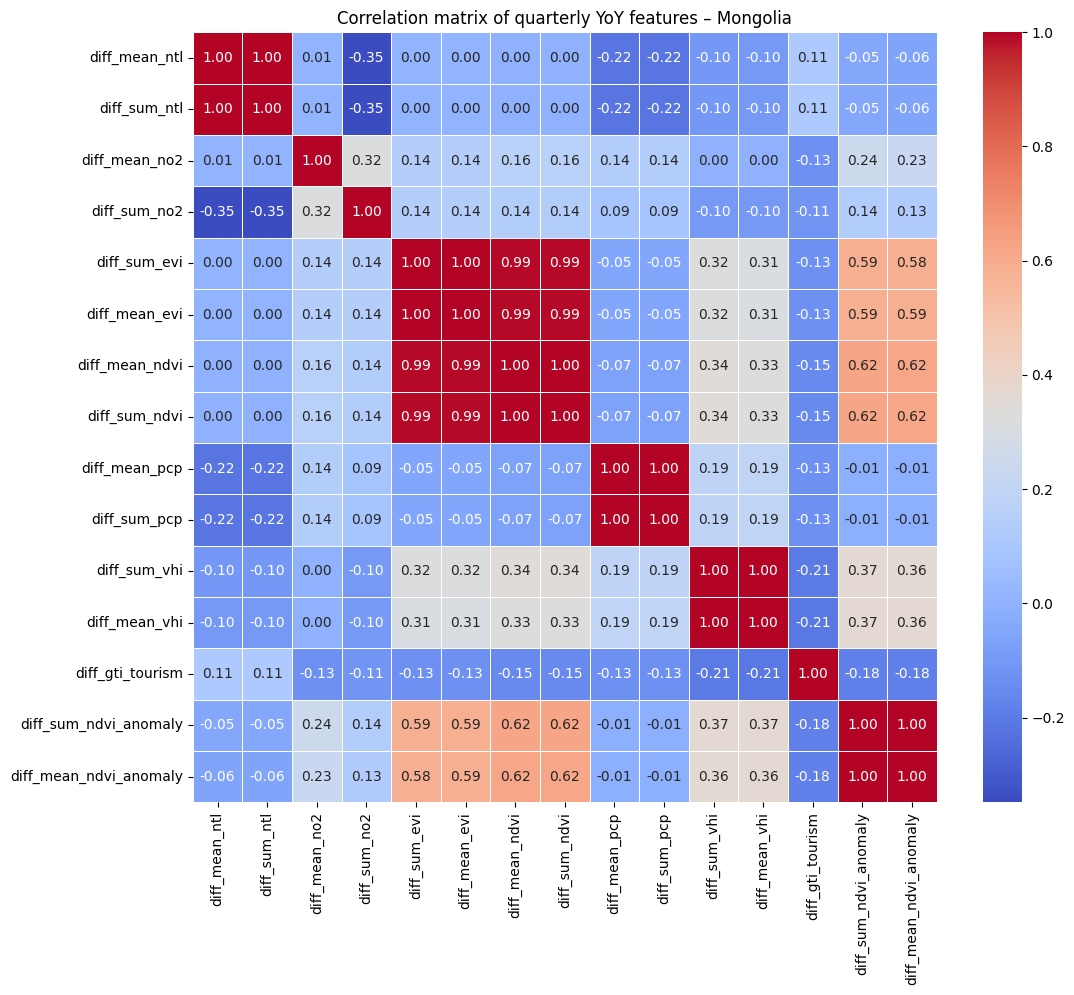

In [43]:
correlation_matrix = final_combined_df2[other_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title(f'Correlation matrix of quarterly YoY features – {CountryName}')
plt.savefig(f"{output_path}/{CountryCode}_correlation_matrix.png", dpi=300, bbox_inches='tight')
plt.show()